In [8]:
from req_functions_from_ApproxSP import *
from tqdm import tqdm
from generate_profiles import *
from euclidean import *
from mallows import *
from AccompliceManipulation import *
from impartial import *

[[[3, 1, 2], [3, 1, 2], [3, 2, 1]], [[1, 2, 3], [1, 2, 3], [2, 1, 3]]]
[[3, 1, 2], [3, 1, 2], [3, 2, 1]] [[1, 2, 3], [1, 2, 3], [2, 1, 3]]
<class 'list'> <class 'list'>


100%|██████████| 6/6 [17:47<00:00, 177.90s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.968, 0.992, 0.856, 0.356, 0.218], [0.0, 1.0, 1.626, 1.398, 0.784, 0.426], [0.0, 0.804, 1.458, 1.664, 1.342, 0.82], [0.0, 0.366, 0.81, 1.288, 2.072, 2.326], [0.0, 0.118, 0.314, 0.628, 1.638, 2.436]]


Mallows Accomplice

In [11]:
def generate_ic_votes(num_agents: int = None, **kwargs):

    return [list(np.random.permutation(num_agents) + 1) for _ in range(num_agents)]

In [ ]:
##Mallows Accomplice Average Number of Manipulator and Accomplice Pairs

number = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice) ##only thing that will change is using accomplice_manipulation here
                    if result [0]!= matching:
                        cnt = cnt+1
            count.append(cnt)
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)

100%|██████████| 6/6 [34:02:14<00:00, 20422.37s/it]  

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.072, 0.318, 0.828, 1.094, 0.872], [0.0, 0.226, 0.86, 1.404, 3.026, 2.064], [0.0, 0.314, 1.198, 2.906, 5.15, 6.044], [0.0, 0.23, 1.302, 4.708, 11.39, 13.998], [0.0, 0.15, 0.968, 3.34, 17.404, 37.036]]


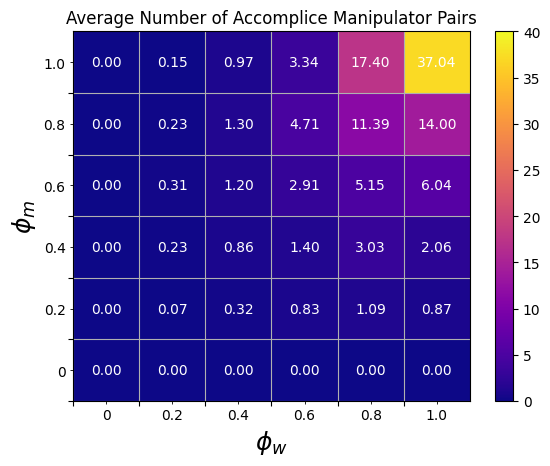

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=40))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Accomplice Manipulator Pairs') #reduce scale of this one so easier to see variation in the rest of the graph
plt.grid(True)

plt.savefig("number_of_manipulators_accomplice_pairs_Mallows.pdf", format='pdf')
plt.show()

In [30]:
import json

In [37]:
def clean_pref(pref):
    return [[int(x) for x in lst] for lst in pref]

In [42]:
##Mallows Accomplice Average Number of Manipulators

data = []
number = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt_pair=0
            count_woman = 0
            m_pref = [generate_ic_votes(n)[0]]*n
            w_pref = [generate_ic_votes(n)[0]]*n
            mpref= mallows_votes(m_pref, phi1)
            wpref= mallows_votes(w_pref, phi2)
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice) ##only thing that will change is using accomplice_manipulation here
                    if result [0]!= matching:
                        cnt_pair = cnt_pair+1
                if cnt_pair > 0:
                    count_woman += 1
            count.append(count_woman)
            data.append([float(phi1), float(phi2), json.dumps(clean_pref(mpref)), json.dumps(clean_pref(wpref)), int(samples), int(count_woman)])
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)

100%|██████████| 6/6 [34:20:39<00:00, 20606.59s/it]  

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.87, 2.218, 3.412, 2.602, 1.302], [0.0, 1.574, 4.922, 5.798, 5.886, 4.158], [0.0, 2.94, 6.372, 9.802, 8.79, 7.174], [0.0, 1.796, 4.942, 9.022, 13.466, 13.8], [0.0, 1.058, 3.358, 7.85, 14.956, 21.518]]


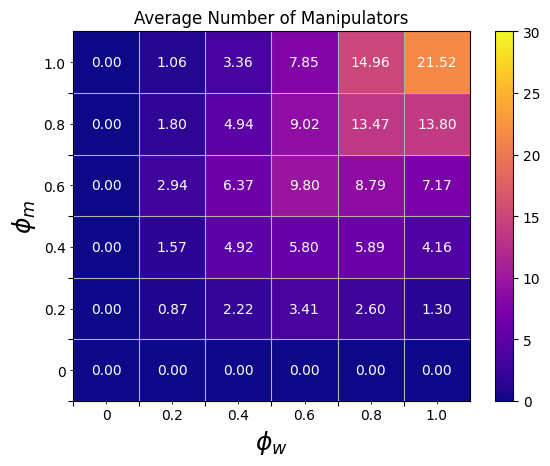

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=30))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("number_of_manipulators_Mallows.pdf", format='pdf')
plt.show()

In [44]:
import pandas as pd

df1 = pd.DataFrame(data, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "manipulation_count"])
df1.to_csv('mallows_accomplice.csv', index=False)

Mallows MD Accomplice

In [10]:
import json

In [ ]:
##Mallows MD Accomplice Average number of manipulator and accomplice pairs

data = []
numberMD = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            pref=generate_mallows_asymmetric_votes(num_agents=n, phi_m=phi1, phi_w=phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
            count.append(cnt)
            data.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, cnt])
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    numberMD.append(number_phi)
print(numberMD)

100%|██████████| 6/6 [10:41:50<00:00, 6418.50s/it]  

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [12.944, 8.01, 7.968, 9.144, 14.746, 22.26], [17.264, 16.72, 14.76, 15.706, 22.508, 35.846], [30.708, 26.182, 26.216, 26.534, 34.83, 42.194], [48.494, 44.926, 42.164, 39.934, 42.742, 37.798], [44.866, 42.128, 39.674, 38.48, 37.122, 32.778]]


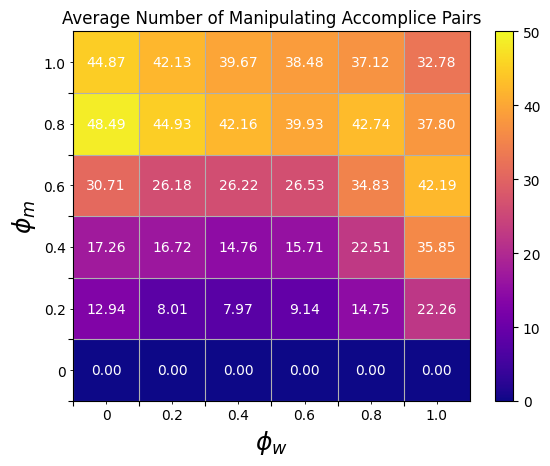

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(numberMD)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=50))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulating Accomplice Pairs')
plt.grid(True)

plt.savefig("number_of_manipulators_accomplice_pairs_MallowsMD.pdf", format='pdf')
plt.show()

In [ ]:
##Mallows MD Accomplice Average number of manipulator 

data = []
numberMD = []
n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            count_woman = 0
            pref=generate_mallows_asymmetric_votes(num_agents=n, phi_m=phi1, phi_w=phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt > 0:
                    count_woman += 1
            count.append(count_woman)
            data.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_woman])
        #number_phi.append(sum(count) / len(count))
        if len(count)>0: #checking for the two counts can both be checked under this if statement
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    numberMD.append(number_phi) #skip regular euclidean, can reduce dimensions for some things
print(numberMD) #to run both pairs and number manipulators at the same time, need two "count", "number_phi" and "numberMD"

100%|██████████| 6/6 [5:22:32<00:00, 3225.48s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [10.138, 9.672, 11.86, 13.274, 14.408, 13.516], [15.57, 14.448, 15.966, 16.656, 17.948, 18.678], [19.274, 18.58, 19.356, 21.022, 21.034, 20.266], [22.11, 21.296, 22.424, 23.038, 22.782, 21.104], [20.786, 20.25, 21.24, 21.034, 21.696, 20.914]]


In [7]:
import pandas as pd

df1 = pd.DataFrame(data, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "manipulation_count"])
df1.to_csv('mallows_MD_accomplice.csv', index=False)

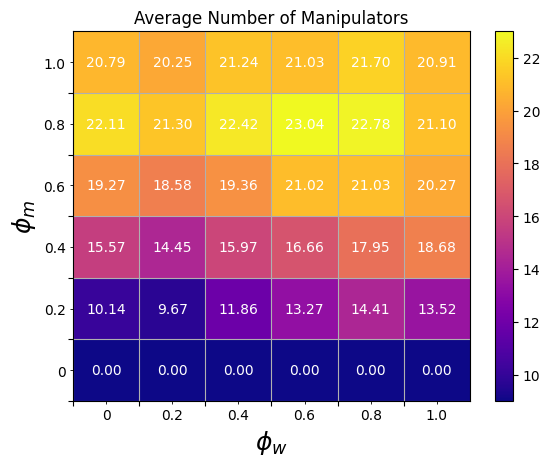

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(numberMD)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=9, vmax=23))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_manipulators_MallowsMD.pdf", format='pdf')
plt.show()

In [ ]:
## Euclidean Mallows Accomplice for d = 2

data = []
numberEM = []
numberEM_pairs = []
n=30
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count=[]
        count_pairs = []
        ct=[]
        for samples in range (500):
            count_woman = 0
            cnt_pairs = 0
            pref=generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt=0
                for accomplice in range(1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result [0]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            count.append(count_woman)
            data.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi.append(0)
            number_phi_pairs.append(0)
    numberEM.append(number_phi)
    numberEM_pairs.append(number_phi_pairs)
print(numberEM)
print(numberEM_pairs)

100%|██████████| 6/6 [6:52:37<00:00, 4126.23s/it]  

[[0.0, 0.082, 0.318, 0.694, 1.594, 4.724], [0.088, 0.18, 0.442, 0.83, 1.786, 4.628], [0.238, 0.36, 0.582, 0.928, 1.756, 5.29], [0.554, 0.64, 0.914, 1.292, 1.928, 5.59], [1.25, 1.266, 1.662, 1.972, 3.022, 6.288], [5.568, 5.646, 5.512, 5.356, 6.022, 6.19]]
[[0.0, 0.114, 0.492, 1.672, 7.05, 32.632], [0.128, 0.266, 0.742, 2.17, 7.466, 30.458], [0.412, 0.706, 1.138, 2.588, 7.94, 37.132], [1.132, 1.332, 2.032, 3.976, 8.17, 34.958], [4.28, 4.604, 5.538, 7.218, 14.508, 37.842], [30.482, 30.498, 30.992, 28.904, 34.532, 32.754]]


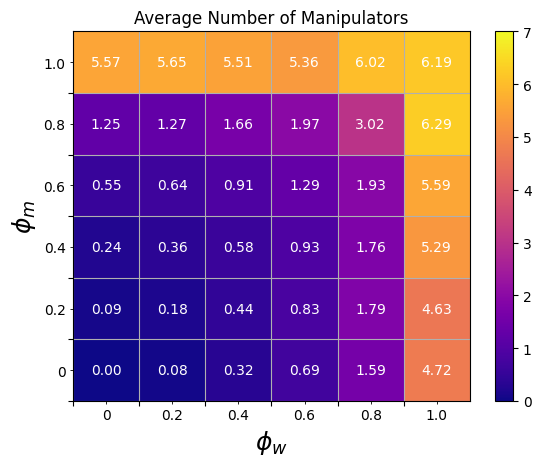

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberEM)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=7))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

plt.savefig("accomplice_manipulators_Euclidean_Mallows.pdf", format='pdf')
plt.show()

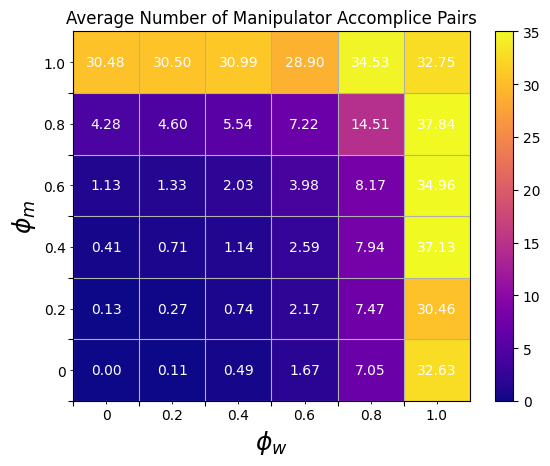

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(numberEM_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=35))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulator Accomplice Pairs')
plt.grid(True)

plt.savefig("accomplice_manipulators_pairs_euclidean_mallows.pdf", format='pdf')
plt.show()

In [20]:
import pandas as pd

df2 = pd.DataFrame(data, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "count_pairs"])
df2.to_csv('euclidean_mallows_accomplice.csv', index=False)

In [40]:
import pandas as pd
import json
from tqdm import tqdm

# Load your saved data CSV
df = pd.read_csv('euclidean_mallows_accomplice.csv')

# Convert JSON strings back to Python lists
df['mpref'] = df['mpref'].apply(json.loads)
df['wpref'] = df['wpref'].apply(json.loads)

# Unique phi1 and phi2 values (if needed for grouping)
phi1_list = sorted(df['phi_m'].unique())
phi2_list = sorted(df['phi_w'].unique())

numberEM_try = []
numberEM_pairs_try = []

for phi1 in tqdm(phi1_list):
    number_phi = []
    number_phi_pairs = []
    
    for phi2 in tqdm(phi2_list):
        # Filter rows with current phi1 and phi2
        subset = df[(df['phi_m'] == phi1) & (df['phi_w'] == phi2)]
        
        if len(subset) > 0:
            # Use mean of count_woman and cnt_pairs
            avg_count = subset['count_woman'].mean()
            avg_pairs = subset['count_pairs'].mean()
        else:
            avg_count = 0
            avg_pairs = 0
        
        number_phi.append(avg_count)
        number_phi_pairs.append(avg_pairs)
    
    numberEM_try.append(number_phi)
    numberEM_pairs_try.append(number_phi_pairs)

print(numberEM_try)
print(numberEM_pairs_try)         


100%|██████████| 6/6 [00:00<00:00, 299.63it/s]

[[0.0, 0.082, 0.318, 0.694, 1.594, 4.724], [0.088, 0.18, 0.442, 0.83, 1.786, 4.628], [0.238, 0.36, 0.582, 0.928, 1.756, 5.29], [0.554, 0.64, 0.914, 1.292, 1.928, 5.59], [1.25, 1.266, 1.662, 1.972, 3.022, 6.288], [5.568, 5.646, 5.512, 5.356, 6.022, 6.19]]
[[0.0, 0.114, 0.492, 1.672, 7.05, 32.632], [0.128, 0.266, 0.742, 2.17, 7.466, 30.458], [0.412, 0.706, 1.138, 2.588, 7.94, 37.132], [1.132, 1.332, 2.032, 3.976, 8.17, 34.958], [4.28, 4.604, 5.538, 7.218, 14.508, 37.842], [30.482, 30.498, 30.992, 28.904, 34.532, 32.754]]


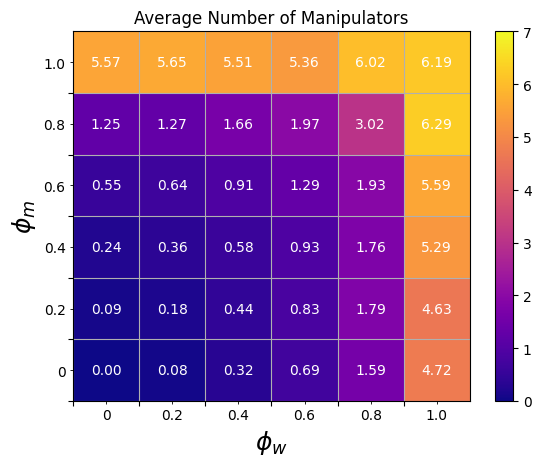

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberEM_try)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=7))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

#plt.savefig("accomplice_manipulators_Euclidean_Mallows.pdf", format='pdf')
plt.show()

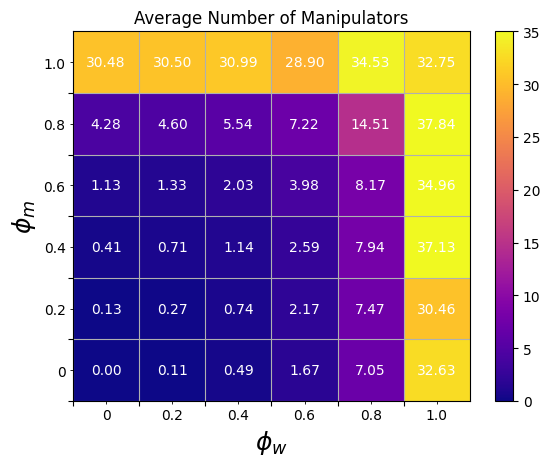

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0] 
    
w_number = np.array(numberEM_pairs_try)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=35))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Average Number of Manipulators')
plt.grid(True)

#plt.savefig("accomplice_manipulators_Euclidean_Mallows.pdf", format='pdf')
plt.show()

In [27]:
#Reverse Euclidean

number_reverse_euclidean = []
number_reverse_euclidean_pairs = []
data_RE = []
n=30
p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for p in tqdm(p_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            count_woman = 0
            cnt_pairs = 0
            pref = generate_reverse_euclidean_votes(n, d, 'uniform', 0.5, p)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count.append(count_woman)
            count_pairs.append(cnt_pairs)
            data_RE.append([d, p, json.dumps(mpref), json.dumps(wpref), samples, count_woman, cnt_pairs])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    number_reverse_euclidean.append(number_d)
    number_reverse_euclidean_pairs.append(number_d_pairs)
print(number_reverse_euclidean)
print(number_reverse_euclidean_pairs)


100%|██████████| 5/5 [12:11:18<00:00, 8775.73s/it]  

[[0.0, 1.04, 1.728, 2.16, 1.152, 0.0], [0.0, 1.834, 3.218, 3.024, 1.922, 0.0], [0.0, 2.128, 3.354, 3.478, 2.194, 0.0], [0.0, 2.436, 3.546, 3.924, 2.124, 0.0], [0.0, 2.522, 3.898, 3.792, 2.176, 0.0]]
[[0.0, 5.722, 10.68, 14.002, 7.984, 0.0], [0.0, 10.854, 19.216, 20.78, 13.004, 0.0], [0.0, 13.214, 21.894, 21.776, 15.426, 0.0], [0.0, 16.058, 23.752, 25.31, 13.822, 0.0], [0.0, 14.698, 24.096, 23.626, 13.944, 0.0]]


In [28]:
import pandas as pd

df3 = pd.DataFrame(data, columns=["dimension", "proportion", "mpref", "wpref", "sample", "count_woman", "cnt_pairs"])
df3.to_csv('reverse_euclidean_accomplice.csv', index=False)

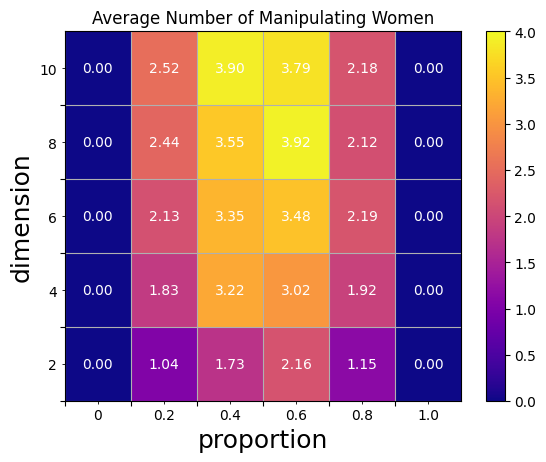

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
    
w_number = np.array(number_reverse_euclidean)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=4))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(p_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('proportion', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_accomplice_reverse_euclidean.pdf", format='pdf')
plt.show()

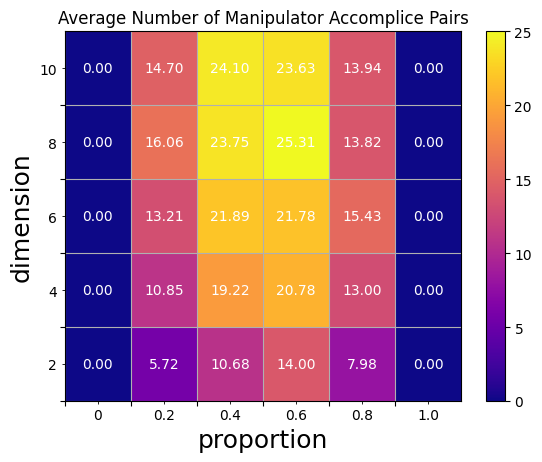

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

p_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list  = [2, 4, 6, 8, 10]
    
w_number = np.array(number_reverse_euclidean_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=25))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(p_list, minor=True)
ax.set_yticklabels(d_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('proportion', fontsize=18)
plt.ylabel('dimension', fontsize=18)
plt.title('Average Number of Manipulator Accomplice Pairs')
plt.grid(True)

plt.savefig("number_of_manipulators_accomplice_reverse_euclidean_pairs.pdf", format='pdf')
plt.show()

In [30]:
import numpy as np

def generate_expectation_votes(num_agents: int = None,
                               dim: int = None,
                               space='uniform',
                               std: float = None,
                               phi=0.5,
                               **kwargs):
    name = f'{dim}d_{space}'

    left_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    left_agents_wishes = np.zeros([num_agents, dim])

    right_agents_reality = np.array([get_uniform_point(dim) for _ in range(num_agents)])
    right_agents_wishes = np.zeros([num_agents, dim])

    for v in range(num_agents):
        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        left_agents_wishes[v][0] = np.random.normal(left_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        left_agents_wishes[v][1] = np.random.normal(left_agents_reality[v][1], std)

        # while agents_wishes[v][0] <= 0 or agents_wishes[v][0] >= 1:
        right_agents_wishes[v][0] = np.random.normal(right_agents_reality[v][0], std)
        # while agents_wishes[v][1] <= 0 or agents_wishes[v][1] >= 1:
        right_agents_wishes[v][1] = np.random.normal(right_agents_reality[v][1], std)

    left_votes = np.zeros([num_agents, num_agents], dtype=int)
    right_votes = np.zeros([num_agents, num_agents], dtype=int)
    distances = np.zeros([num_agents, num_agents], dtype=float)

    for v in range(num_agents):
        for c in range(num_agents):
            left_votes[v][c] = c
            distances[v][c] = np.linalg.norm(right_agents_reality[c] - left_agents_wishes[v])
        left_votes[v] = [x for _, x in sorted(zip(distances[v], left_votes[v]))]

    for v in range(num_agents):
        for c in range(num_agents):
            right_votes[v][c] = c
            distances[v][c] = np.linalg.norm(left_agents_reality[c] - right_agents_wishes[v])
        right_votes[v] = [x for _, x in sorted(zip(distances[v], right_votes[v]))]

    left_votes_lst = [list(row) for row in left_votes]
    right_votes_lst = [list(row) for row in right_votes]


    for i in range(len(left_votes_lst)):
        for j in range(len(left_votes_lst[i])):
            left_votes_lst[i][j] = left_votes_lst[i][j] + 1
    for i in range(len(right_votes_lst)):
        for j in range(len(right_votes_lst[i])):
            right_votes_lst[i][j] = right_votes_lst[i][j] + 1

    return [left_votes_lst, right_votes_lst]

In [ ]:
## Expectations Euclidean

data_EE = []
number_expectations_euclidean = []
number_EE_pairs = []
n = 30
std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for std in tqdm(std_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            cnt = 0
            count_woman = 0
            pref = generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt > 1:
                    count_woman += 1
            count.append(count_woman)
            count_pairs.append(cnt)
            data_EE.append([d, std, mpref, wpref, samples, count_woman])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs)/ len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    number_expectations_euclidean.append(number_d)
    number_EE_pairs.append(number_d_pairs)
print(number_expectations_euclidean)
print(number_EE_pairs)

100%|██████████| 5/5 [20:15:04<00:00, 14580.87s/it]  

[[0.0, 13.106, 16.378, 16.216, 15.434, 13.786], [0.0, 2.228, 6.96, 6.956, 9.066, 9.922], [0.0, 2.48, 5.096, 7.09, 8.482, 7.652], [0.0, 1.778, 4.326, 6.336, 6.808, 8.368], [0.0, 1.82, 4.006, 5.272, 7.338, 6.958]]
[[0.0, 10.498, 18.858, 19.808, 18.716, 14.746], [0.0, 0.728, 3.448, 3.712, 5.55, 7.11], [0.0, 0.66, 1.99, 3.046, 4.678, 4.666], [0.0, 0.476, 1.496, 2.96, 3.586, 4.674], [0.0, 0.494, 1.322, 2.0, 3.394, 3.934]]
